# Light in a fibre: acceptance angle, step against graded index, and the ray picture of modal dispersion

An optical fibre is a thin glass rod with a core of slightly higher index
than the cladding around it. Light that enters the core at a shallow enough
angle is totally reflected at the boundary again and again and follows the
fibre around bends and over kilometres. This notebook tells that story with
rays. It is the first of a short series on fibres and optical
communication:

- **115 (this notebook):** rays, the numerical aperture, skew rays, step
  against graded index and why rays in a step-index fibre arrive at
  different times,
- **116:** modes: the slab, the step-index fibre, exact vector modes,
  graded-index modes, the mode field diameter and bend loss,
- **117:** dispersion: material, waveguide and intermodal, the
  zero-dispersion wavelength and profiles that move it,
- **118:** pulse broadening and the limit it sets on the bit rate,
- **119:** fibre Bragg gratings,
- **120:** a basic fibre link, from attenuation to the bit error rate.

The sections here:

1. total internal reflection and the numerical aperture, and how much of
   an LED a fibre accepts,
2. meridional, skew and tunnelling rays,
3. rays in a graded-index core,
4. intermodal dispersion from the transit times of rays: step index,
   parabolic and the optimal profile,
5. launch conditions and mode mixing,
6. rays in a bend.

The tools are in `pyoptics.fibres` (profiles, ray helpers, delay formulas)
and `pyoptics.grin` (the ray tracer for graded media). Units follow the
habits of fibre optics: the cross section in µm, fibre lengths in km,
times in ps or ns.

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt

from pyoptics import fibres, grin, sketch

plt.rcParams.update({"figure.dpi": 80, "font.size": 11, "figure.facecolor": "white",
                     "axes.facecolor": "#fcfcfb", "savefig.facecolor": "white",
                     "axes.spines.top": False, "axes.spines.right": False})
BLUE, RED, GREEN, ORANGE, PURPLE, GREY = "#2a7ab9", "#d6604d", "#5aa469", "#e0a000", "#8e5ba8", "0.45"
t_start = time.time()
rng = np.random.default_rng(115)

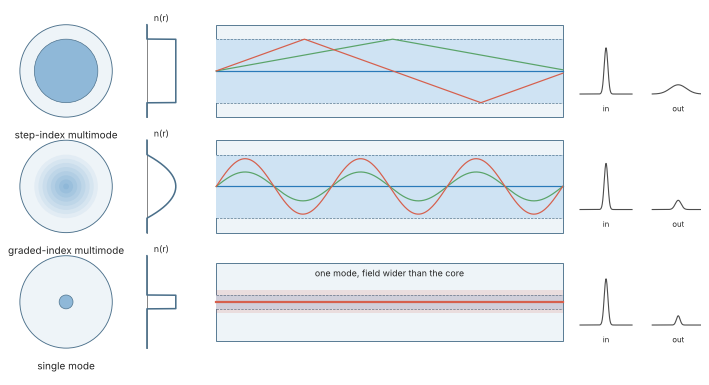

In [2]:
fig, ax = plt.subplots(figsize=(13, 6))
sketch.fibre_types(ax)
plt.show()

The three classic fibres. In the **step-index multimode** fibre the core
(tens of µm) carries many ray directions; the steep ones travel a longer
zigzag path and arrive late, so a short pulse comes out long. In the
**graded-index multimode** fibre the index falls from the axis outwards:
the steep rays bend back smoothly, travel farther but through faster glass,
and arrive almost together. The **single-mode** fibre has a core of only
about 8 µm, so thin that the ray picture breaks down and only one mode
propagates (notebook 116, fibre modes).

## 1. Total internal reflection and the numerical aperture

A ray in the core (index $n_1$) meets the cladding ($n_2 < n_1$) at the
angle of incidence $90° - \theta_1$, where $\theta_1$ is its angle to the
axis. It is totally reflected if $\sin(90° - \theta_1) = \cos\theta_1
\ge n_2/n_1$. At the end face, Snell's law $n_0\sin\theta_0 = n_1
\sin\theta_1$ turns this into the acceptance cone

$$
n_0\sin\theta_{max} = \sqrt{n_1^2 - n_2^2} = \mathrm{NA}
= n_1\sqrt{2\Delta}, \qquad \Delta = \frac{n_1^2 - n_2^2}{2n_1^2} \approx \frac{n_1 - n_2}{n_1}.
$$

The index step is small: $\Delta$ is 0.3 to 0.4 % in a single-mode fibre
and about 1 to 2 % in a multimode fibre, so the critical angle at the
core boundary is above 80°.

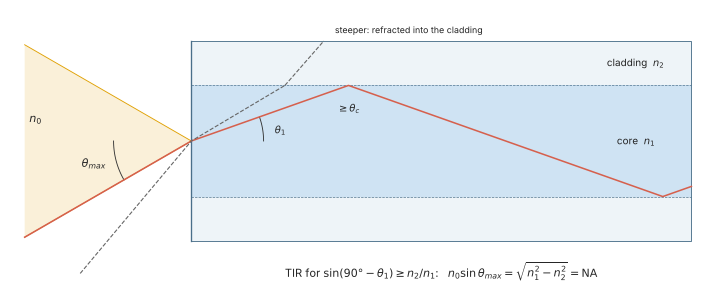

In [3]:
fig, ax = plt.subplots(figsize=(13, 4.6))
sketch.fibre_acceptance(ax)
plt.show()

In [4]:
types = [("single mode (G.652)", 4.1, 1.4495, 1.4440),
         ("multimode 50/125 (OM2 to OM4)", 25.0, 1.4640, 1.4500),
         ("multimode 62.5/125 (OM1)", 31.25, 1.4780, 1.4520),
         ("plastic clad silica (PCS)", 100.0, 1.4570, 1.4040)]
print("{:32s} {:>7s} {:>8s} {:>8s} {:>9s} {:>10s}".format("fibre", "a (µm)", "Delta", "NA",
                                                         "θmax (°)", "θc (°)"))
for name, a, n1, n2 in types:
    NA = np.sqrt(n1**2 - n2**2)
    print("{:32s} {:7.2f} {:8.4f} {:8.3f} {:9.1f} {:10.1f}".format(
        name, a, (n1**2 - n2**2)/(2*n1**2), NA, np.degrees(fibres.acceptance_angle(NA)),
        np.degrees(np.arcsin(n2/n1))))

fibre                             a (µm)    Delta       NA  θmax (°)     θc (°)
single mode (G.652)                 4.10   0.0038    0.126       7.2       85.0
multimode 50/125 (OM2 to OM4)      25.00   0.0095    0.202      11.7       82.1
multimode 62.5/125 (OM1)           31.25   0.0174    0.276      16.0       79.2
plastic clad silica (PCS)         100.00   0.0357    0.389      22.9       74.5


### How much of an LED gets in

A Lambertian source of radiance $L$ (an LED) larger than the core puts
the power $\pi L \sin^2\theta$ per unit area into the cone of half angle
$\theta$, a fraction $\sin^2\theta$ of everything it emits. The core
therefore takes the fraction $\mathrm{NA}^2$ (in air) of the light that
falls on it: 4 % for a 0.2 NA multimode fibre and 1.4 % for a single-mode
fibre. The core accepts the étendue
$G = \pi A\,\mathrm{NA}^2 = \pi^2 a^2\mathrm{NA}^2$ (notebook 83, étendue), which no
lens in front of it can enlarge: an LED as large as the core gains nothing
from a lens. Below, rays from a Lambertian emitter on the end face are
counted after refraction.

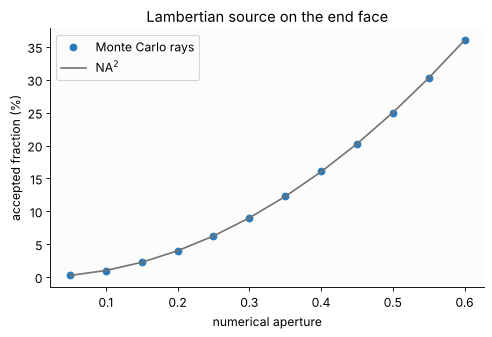

In [5]:
n_rays = 400_000
u = rng.random(n_rays)
sin_theta0 = np.sqrt(u)            # Lambertian: sin^2(theta) uniform
phi = 2*np.pi*rng.random(n_rays)
fractions = []
NAs = np.linspace(0.05, 0.6, 12)
for NA in NAs:
    n1 = 1.46
    n2 = np.sqrt(n1**2 - NA**2)
    sin_theta1 = sin_theta0/n1         # Snell at the end face, n0 = 1
    guided = np.sqrt(1 - sin_theta1**2) >= n2/n1
    fractions.append(guided.mean())

fig, ax = plt.subplots(figsize=(7, 4.2))
ax.plot(NAs, np.array(fractions)*100, "o", color=BLUE, label="Monte Carlo rays")
ax.plot(NAs, NAs**2*100, color=GREY, label=r"NA$^2$")
ax.set_xlabel("numerical aperture"); ax.set_ylabel("accepted fraction (%)")
ax.set_title("Lambertian source on the end face")
ax.legend()
plt.show()

## 2. Meridional, skew and tunnelling rays

A **meridional** ray passes through the axis and stays in one plane: it is
the zigzag of the textbook drawings. Most rays are **skew**: they never
meet the axis but spiral along the fibre. Seen along the axis, a skew ray in
a step-index core is a polygon of equal chords that touches a circle of
radius $r_{min}$. Two quantities stay the same all along the ray:

$$
\bar\beta = n_1\cos\theta_z, \qquad \bar l = n_1\sin\theta_z\,\frac{r_{min}}{a},
$$

with $\theta_z$ the angle to the axis. $\bar\beta$ is the ray version of
the propagation constant $\beta/k$ of a mode, $\bar l$ that of the
angular momentum (the azimuthal mode index $l$).

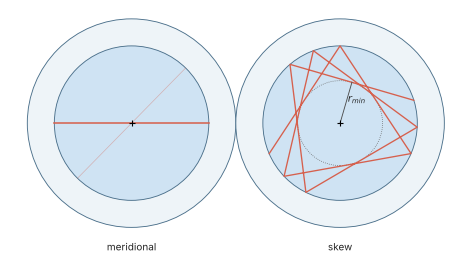

In [6]:
fig, ax = plt.subplots(figsize=(10, 4.2))
sketch.skew_ray_end_view(ax)
plt.show()

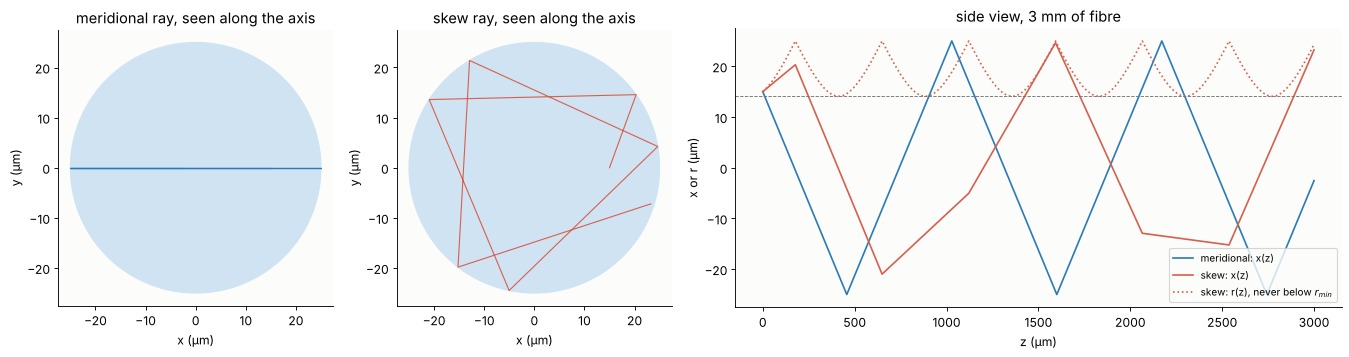

skew ray: r_min/a = 0.5638 at every chord (spread 3.5e-12), 6 reflections in 3 mm
both rays take the same time: L n1/(c cos θz) depends only on θz


In [7]:
a, n1, n2 = 25.0, 1.464, 1.450
theta_z = np.radians(5.0)
start = np.array([0.6*a, 0.0, 0.0])
skew_dir = np.array([np.sin(theta_z)*np.cos(np.radians(70)), np.sin(theta_z)*np.sin(np.radians(70)),
                     np.cos(theta_z)])
merid_dir = np.array([-np.sin(theta_z), 0.0, np.cos(theta_z)])
skew = fibres.step_ray(a, start, skew_dir, 3000.0)
merid = fibres.step_ray(a, start, merid_dir, 3000.0)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.6), gridspec_kw={"width_ratios": [1, 1, 2.2]})
for ax, pts, name, c in ((axes[0], merid, "meridional", BLUE), (axes[1], skew, "skew", RED)):
    t = np.linspace(0, 2*np.pi, 200)
    ax.fill(a*np.cos(t), a*np.sin(t), color="#cfe3f3")
    ax.plot(pts[:, 0], pts[:, 1], color=c, lw=1)
    ax.set_aspect("equal"); ax.set_title(name + " ray, seen along the axis")
    ax.set_xlabel("x (µm)"); ax.set_ylabel("y (µm)")
d = np.diff(skew, axis=0)
r_min = np.abs(skew[:-1, 0]*d[:, 1] - skew[:-1, 1]*d[:, 0])/np.hypot(d[:, 0], d[:, 1])
axes[2].plot(merid[:, 2], merid[:, 0], color=BLUE, label="meridional: x(z)")
axes[2].plot(skew[:, 2], skew[:, 0], color=RED, label="skew: x(z)")
zd = np.linspace(0, 3000, 3000)
r_dense = np.hypot(np.interp(zd, skew[:, 2], skew[:, 0]), np.interp(zd, skew[:, 2], skew[:, 1]))
axes[2].plot(zd, r_dense, color=RED, ls=":", label="skew: r(z), never below $r_{min}$")
axes[2].axhline(r_min[0], color=GREY, lw=0.8, ls="--")
axes[2].set_xlabel("z (µm)"); axes[2].set_ylabel("x or r (µm)"); axes[2].legend(fontsize=9, loc="lower right")
axes[2].set_title("side view, 3 mm of fibre")
plt.tight_layout()
plt.show()
print("skew ray: r_min/a = {:.4f} at every chord (spread {:.1e}), {} reflections in 3 mm".format(
      r_min[0]/a, np.ptp(r_min)/a, len(skew) - 2))
print("both rays take the same time: L n1/(c cos θz) depends only on θz")

### Bound, tunnelling and refracting rays

Whether a ray stays in the core depends on both invariants (Snyder and
Love). It is **bound** if $\bar\beta \ge n_2$: then the angle of
incidence at the boundary is above the critical angle for every ray,
meridional or skew. A skew ray meets the curved boundary at a more grazing
angle than its $\theta_z$ suggests, so skew rays with
$n_2^2 - \bar l^2 \le \bar\beta^2 < n_2^2$ are totally reflected too. They
are **tunnelling** rays: like a wave at a curved interface (or a particle
at a potential barrier) they leak out slowly, over centimetres to
kilometres depending on how close they are to the bound region, so a short
fibre seems to have a larger NA than a long one. All other rays
**refract** out within millimetres.

Below, a Lambertian emitter that covers the end face (uniform over the core,
all directions) is sorted by the two invariants.

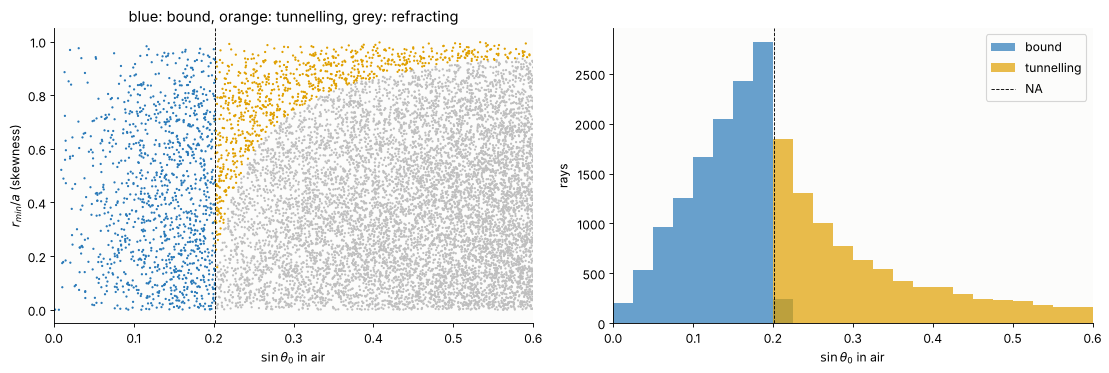

bound: 4.05 % of the rays (NA^2 = 4.08 %), tunnelling: 3.41 %


In [8]:
n_rays = 300_000
r = a*np.sqrt(rng.random(n_rays))
psi = 2*np.pi*rng.random(n_rays)
sin_t0 = np.sqrt(rng.random(n_rays))
az = 2*np.pi*rng.random(n_rays)
sin_tz = sin_t0/n1
beta_bar = n1*np.sqrt(1 - sin_tz**2)
# direction of the transverse part against the position vector
x0, y0 = r*np.cos(psi), r*np.sin(psi)
dx, dy = np.cos(az), np.sin(az)
rmin = np.abs(x0*dy - y0*dx)
l_bar = n1*sin_tz*rmin/a
kind = fibres.ray_class(beta_bar, l_bar, n1, n2)
NA = np.sqrt(n1**2 - n2**2)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
sel = slice(0, 30000)
colors = np.array([BLUE, ORANGE, "0.75"])
axes[0].scatter(sin_t0[sel], (rmin/a)[sel], c=colors[kind[sel]], s=1)
axes[0].axvline(NA, color="k", lw=0.8, ls="--")
axes[0].set_xlabel(r"$\sin\theta_0$ in air"); axes[0].set_ylabel(r"$r_{min}/a$ (skewness)")
axes[0].set_xlim(0, 0.6)
axes[0].set_title("blue: bound, orange: tunnelling, grey: refracting")
bins = np.linspace(0, 1, 41)
for k, name, c in ((0, "bound", BLUE), (1, "tunnelling", ORANGE)):
    axes[1].hist(sin_t0[kind == k], bins, color=c, alpha=0.7, label=name)
axes[1].axvline(NA, color="k", lw=0.8, ls="--", label="NA")
axes[1].set_xlabel(r"$\sin\theta_0$ in air"); axes[1].set_ylabel("rays"); axes[1].set_xlim(0, 0.6)
axes[1].legend()
plt.tight_layout()
plt.show()
print("bound: {:.2f} % of the rays (NA^2 = {:.2f} %), tunnelling: {:.2f} %".format(
      100*np.mean(kind == 0), 100*NA**2, 100*np.mean(kind == 1)))

The bound rays are exactly those inside the acceptance cone, $\mathrm{NA}^2$
of the light, independent of their skewness. Tunnelling rays add about as
much again, at larger angles and only for strongly skew rays. A short
piece of fibre transmits them; after some metres most are gone.
Measurements of the NA therefore specify the length (ISO/IEC 60793-1-43
uses 2 m with mode stripping).

## 3. Rays in a graded-index core

A graded-index fibre has the power law profile

$$
n^2(r) = n_1^2\left(1 - 2\Delta\left(\frac{r}{a}\right)^\alpha\right) \quad (r < a),
\qquad n = n_2 \quad (r \ge a).
$$

$\alpha = 2$ is the parabolic profile, $\alpha \to \infty$ the step. In the
parabolic core the paraxial ray equation $x'' = -(2\Delta/a^2)x$ gives
sinusoids with the pitch $2\pi a/\sqrt{2\Delta}$, about 1.1 mm for a
50 µm core with $\Delta = 1\,\%$: the GRIN rod of notebook 77 (GRIN optics), made long.
`Fibre.index_field()` hands the profile to `grin.trace()`, which follows
rays exactly (not paraxially).

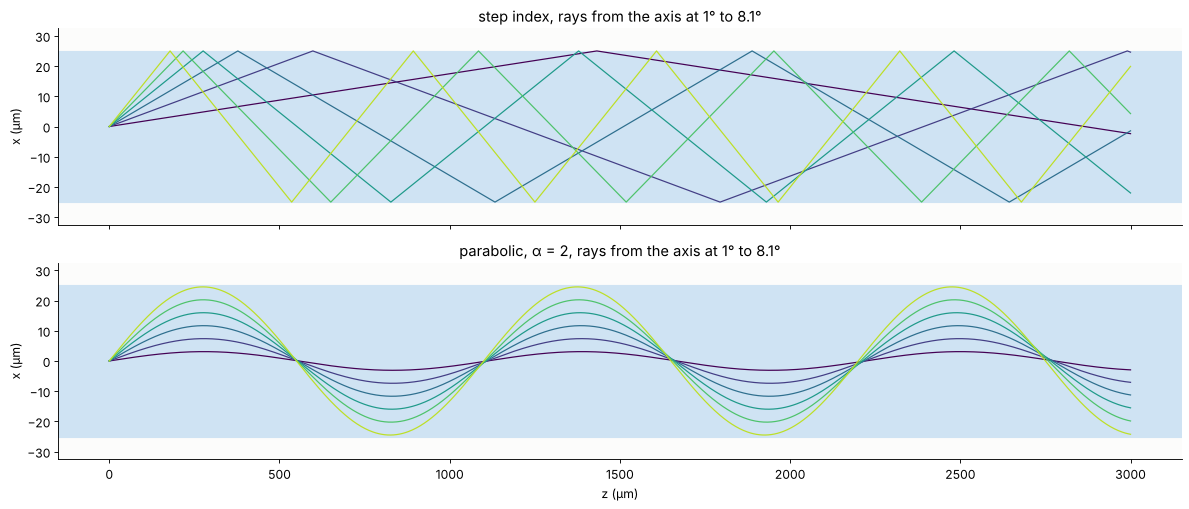

paraxial pitch 2πa/sqrt(2Δ) = 1111 µm, NA = 0.208


In [9]:
a, n1, Delta = 25.0, 1.47, 0.01
n2 = n1*np.sqrt(1 - 2*Delta)
wl = 0.85
step_f = fibres.step_index(a, n1, n2)
para = fibres.graded_index(a, 2.0, n1, n2)
NA = para.NA(wl)
theta_c = np.arccos(n2/n1)
angles = np.radians(np.linspace(1, 0.98*np.degrees(theta_c), 6))

fig, axes = plt.subplots(2, 1, figsize=(15, 6.5), sharex=True)
L = 3000.0
rays = grin.trace(para.index_field(wl), np.zeros((len(angles), 2)),
                  np.c_[np.sin(angles), np.cos(angles)], 2.0, stop=lambda R: R[:, -1] - L)
cols = plt.cm.viridis(np.linspace(0, 0.9, len(angles)))
for i, c in enumerate(cols):
    axes[1].plot(rays.path[:, i, 1], rays.path[:, i, 0], color=c, lw=1.1)
    pts = fibres.step_ray(a, [0, 0, 0], [np.sin(angles[i]), 0, np.cos(angles[i])], L)
    axes[0].plot(pts[:, 2], pts[:, 0], color=c, lw=1.1)
for ax, name in ((axes[0], "step index"), (axes[1], "parabolic, α = 2")):
    ax.axhspan(-a, a, color="#cfe3f3", zorder=0)
    ax.set_ylabel("x (µm)"); ax.set_title(name + f", rays from the axis at 1° to {np.degrees(theta_c):.1f}°")
    ax.set_ylim(-1.3*a, 1.3*a)
axes[1].set_xlabel("z (µm)")
plt.tight_layout()
plt.show()
print("paraxial pitch 2πa/sqrt(2Δ) = {:.0f} µm, NA = {:.3f}".format(2*np.pi*a/np.sqrt(2*Delta), NA))

In the parabolic core all rays from the axis cross it again at nearly
the same points (they would exactly in the hyperbolic secant profile,
notebook 77, GRIN optics), and the steeper rays have a slightly *shorter* pitch: their
invariant $\bar\beta = n_1\cos\theta_z$ is smaller and the exact pitch is
$2\pi a\bar\beta/(n_1\sqrt{2\Delta})$.

## 4. Intermodal dispersion in the ray picture

A ray travelling at the angle $\theta_z$ through a step-index core of
length $L$ needs $t = Ln_1/(c\cos\theta_z)$. The steepest bound ray
($\cos\theta_z = n_2/n_1$) arrives later than the axial ray by

$$
\Delta t = \frac{Ln_1}{c}\left(\frac{n_1}{n_2} - 1\right) \approx \frac{L n_1\Delta}{c},
$$

49 ns per km for $\Delta = 1\,\%$. A pulse of 1 ns would be spread over 50
within a kilometre: the bit rate of such a link is limited to some
10 Mb/s·km.

In a graded core the steep rays take longer paths, but through glass of
lower index, where light is faster. The transit time of a ray is its
optical path over $c$ (without material dispersion), which `grin.trace()`
accumulates. For the infinite parabola the time per length is exactly
$(n_1^2 + \bar\beta^2)/(2\bar\beta c)$, which differs from $n_1/c$ only to
second order in $\Delta$: the full spread is $Ln_1\Delta^2/(2c)$, 0.25 ns
per km instead of 49.

The time per length is averaged over whole periods: rays are traced from
the axis over about four pitches, and the optical path is taken at the last
axis crossing.

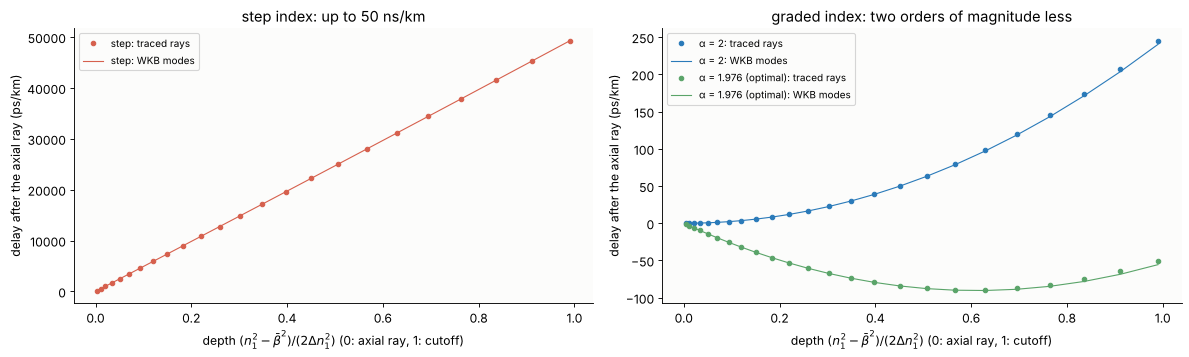

step spread, rays: 49094 ps/km (formula L n1 (n1/n2 - 1)/c = 49782)


In [10]:
def ray_delays(fibre, angles, L=4500.0, step=1.0):
    """Transit time (ps/km) of meridional rays from the axis, over whole
    half periods."""
    rays = grin.trace(fibre.index_field(wl), np.zeros((len(angles), 2)),
                      np.c_[np.sin(angles), np.cos(angles)], step, stop=lambda R: R[:, -1] - L)
    x, z, opl = rays.path[..., 0], rays.path[..., 1], rays.opl_path
    out = []
    for i in range(len(angles)):
        s = np.nonzero((x[1:-1, i] > 0) != (x[2:, i] > 0))[0] + 1
        j = s[-1]
        f = x[j, i]/(x[j, i] - x[j + 1, i])
        zc = z[j, i] + f*(z[j + 1, i] - z[j, i])
        oc = opl[j, i] + f*(opl[j + 1, i] - opl[j, i])
        out.append(oc/zc)
    return np.array(out)*1E9/fibres.C_UM_PER_PS


angles = np.radians(np.linspace(0.5, 0.995*np.degrees(theta_c), 24))
beta_bar = n1*np.cos(angles)
depth = (n1**2 - beta_bar**2)/(2*Delta*n1**2)          # 0 on the axis, 1 at cutoff
t_axis = n1*1E9/fibres.C_UM_PER_PS
a_opt = fibres.optimal_alpha(Delta)
profiles = [("step", None, RED), ("α = 2", 2.0, BLUE), (f"α = {a_opt:.3f} (optimal)", a_opt, GREEN)]

fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))
for name, alpha, c in profiles:
    if alpha is None:
        tau = fibres.step_ray_delay(angles, n1)
        tau_wkb = fibres.wkb_group_delay(depth, 1E6, Delta, n1)
    else:
        tau = ray_delays(fibres.graded_index(a, alpha, n1, n2), angles)
        tau_wkb = fibres.wkb_group_delay(depth, alpha, Delta, n1)
    ax = axes[0] if alpha is None else axes[1]
    ax.plot(depth, tau - t_axis, "o", color=c, ms=4, label=name + ": traced rays")
    ax.plot(depth, tau_wkb - t_axis, "-", color=c, lw=1, label=name + ": WKB modes")
for ax in axes:
    ax.set_xlabel(r"depth $(n_1^2 - \bar\beta^2)/(2\Delta n_1^2)$ (0: axial ray, 1: cutoff)")
    ax.set_ylabel("delay after the axial ray (ps/km)")
    ax.legend(fontsize=9)
axes[0].set_title("step index: up to 50 ns/km")
axes[1].set_title("graded index: two orders of magnitude less")
plt.tight_layout()
plt.show()
print("step spread, rays: {:.0f} ps/km (formula L n1 (n1/n2 - 1)/c = {:.0f})".format(
      np.ptp(fibres.step_ray_delay(angles, n1)), fibres.step_delay_spread(n1, n2)))

The traced rays lie on the WKB group delay of the modes with the same
propagation constant (Gloge and Marcatili, Olshansky and Keck, used again
in notebook 117, dispersion in fibres),

$$
\frac{\tau}{L} = \frac{N_1}{c}\left[1 + \Delta\,\frac{\alpha - 2}{\alpha + 2}\,\delta
+ \Delta^2\,\frac{3\alpha - 2}{2(\alpha + 2)}\,\delta^2\right],
$$

with $\delta$ the depth of the mode in the profile (the abscissa). For
$\alpha = 2$ the first order term vanishes and the delay grows as
$\Delta^2\delta^2/2$. A slightly smaller $\alpha$ lets the first order term
(negative for $\alpha < 2$) cancel the second order term on average:
$\alpha_{opt} = 2 - 12\Delta/5$ for a material without profile dispersion.
The rays (the dots) and the modes (the lines) agree, because the WKB
approximation *is* the ray picture.

How sensitive is this to the profile? The rms spread of equally excited
modes (`wkb_delay_spread()`) against $\alpha$:

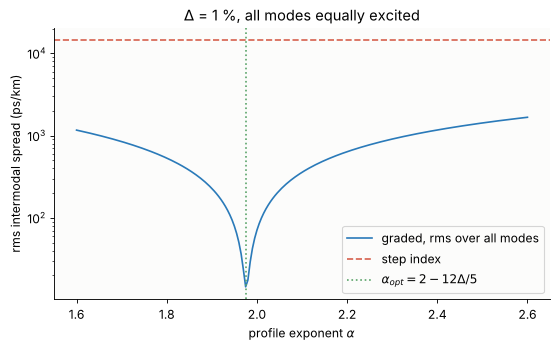

minimum 14.5 ps/km at α = 1.975; α = 2: 70.8 ps/km; step: 14367 ps/km
α off by   1%:   58.7 ps/km
α off by   5%:  286.2 ps/km
α off by  10%:  564.6 ps/km


In [11]:
alphas = np.linspace(1.6, 2.6, 201)
rms = np.array([fibres.wkb_delay_spread(al, Delta, n1) for al in alphas])
rms_step = fibres.wkb_delay_spread(1E6, Delta, n1)
fig, ax = plt.subplots(figsize=(8, 4.4))
ax.semilogy(alphas, rms, color=BLUE, label="graded, rms over all modes")
ax.axhline(rms_step, color=RED, ls="--", label="step index")
ax.axvline(a_opt, color=GREEN, ls=":", label=r"$\alpha_{opt} = 2 - 12\Delta/5$")
ax.set_xlabel(r"profile exponent $\alpha$"); ax.set_ylabel("rms intermodal spread (ps/km)")
ax.set_title(r"$\Delta$ = 1 %, all modes equally excited")
ax.legend()
plt.show()
i = np.argmin(rms)
print("minimum {:.1f} ps/km at α = {:.3f}; α = 2: {:.1f} ps/km; step: {:.0f} ps/km".format(
      rms[i], alphas[i], fibres.wkb_delay_spread(2.0, Delta, n1), rms_step))
for err in (0.01, 0.05, 0.1):
    print("α off by {:4.0%}: {:6.1f} ps/km".format(err, fibres.wkb_delay_spread(a_opt*(1 + err), Delta, n1)))

The optimum is sharp: 5 % away from $\alpha_{opt}$ the spread is an order of
magnitude larger. Real fibres also have profile dispersion (the optimal
$\alpha$ depends on the wavelength, notebook 117, dispersion in fibres) and small dips and
ripples from the deposition process, and the best ones are measured, not
computed: the effective modal bandwidth of 50 µm fibres is
500 MHz·km (OM2), 2000 MHz·km (OM3) and 4700 MHz·km (OM4) at 850 nm,
against about 10 to 20 MHz·km for a step-index fibre. A Gaussian impulse response
of rms width $\sigma$ has the 3 dB bandwidth $0.187/\sigma$, so OM4 means
$\sigma \approx 40$ ps/km, the rms spread of a profile within about 1 % of
$\alpha_{opt}$.

## 5. Launch conditions and mode mixing

How much a pulse spreads depends on which rays carry the light. An LED
fills the whole acceptance cone (an **overfilled launch**), a laser or a
VCSEL only a part of it (a **restricted launch**). Along the fibre, small
bends and index fluctuations scatter the rays into slightly different
angles: the angles diffuse, rays that diffuse beyond the critical angle
are lost, and after a coupling length the angular distribution reaches an
equilibrium independent of the launch. Diffusion also averages the delay
of each ray over many angles, so the spread grows like $\sqrt{L}$ instead
of $L$.

A simple Monte Carlo model of a step-index fibre: each ray gets random
kicks of its angle every 10 m, rays beyond the critical angle are removed,
and the time of flight is accumulated. The mixing (0.1 rad per √km) is
strong, so that the equilibrium is reached within a kilometre; real fibres
mix less, and their equilibrium length is several kilometres.

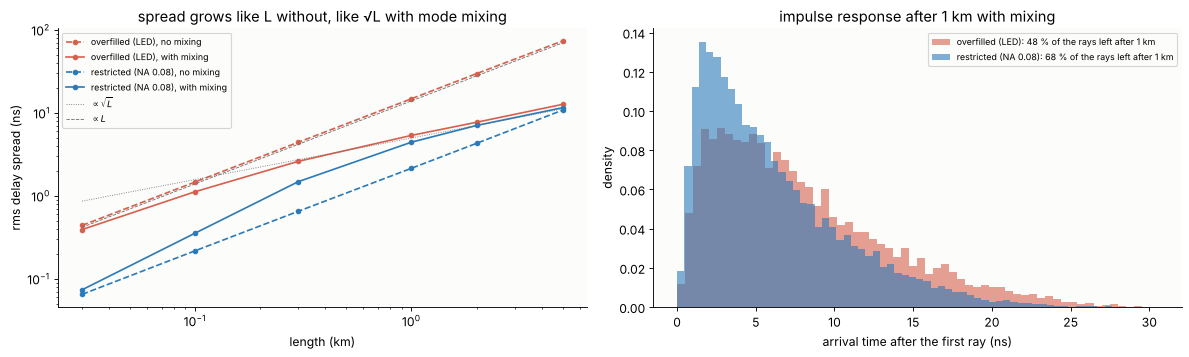

In [12]:
def launch_and_mix(theta_launch_max, L_km, kick_rad_per_sqrt_km, n_rays=20000, dz_km=0.01,
                   rng=rng):
    """Step-index fibre with angular diffusion (2D: one transverse angle).
    Returns the times (ps) of the surviving rays at the end and the fraction
    left."""
    sin_t = rng.uniform(-1, 1, n_rays)*np.sin(theta_launch_max)       # uniform in sin(theta0)
    th = np.arcsin(sin_t/n1)
    t = np.zeros(n_rays)
    alive = np.ones(n_rays, dtype=bool)
    for _ in range(int(round(L_km/dz_km))):
        t += dz_km*1E9/fibres.C_UM_PER_PS*n1/np.cos(th)
        th += rng.standard_normal(n_rays)*kick_rad_per_sqrt_km*np.sqrt(dz_km)
        alive &= np.abs(th) < theta_c
    return t[alive], alive.mean()


NA_air = np.sqrt(n1**2 - n2**2)
lengths = np.array([0.03, 0.1, 0.3, 1.0, 2.0, 5.0])
kick = 0.1
fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))
for name, th0, c in (("overfilled (LED)", np.arcsin(NA_air), RED), ("restricted (NA 0.08)", np.arcsin(0.08), BLUE)):
    for kk, ls in ((0.0, "--"), (kick, "-")):
        rms_t = []
        for Lk in lengths:
            times, left = launch_and_mix(th0, Lk, kk, n_rays=20000)
            rms_t.append(np.std(times))
        lab = name + (", no mixing" if kk == 0 else ", with mixing")
        axes[0].loglog(lengths, np.array(rms_t)/1E3, ls, color=c, marker="o", ms=4, label=lab)
    times, left = launch_and_mix(th0, 1.0, kick)
    axes[1].hist((times - times.min())/1E3, 60, color=c, alpha=0.6, density=True,
                 label=f"{name}: {100*left:.0f} % of the rays left after 1 km")
axes[0].loglog(lengths, 5*lengths**0.5, color=GREY, lw=0.8, ls=":", label=r"$\propto\sqrt{L}$")
axes[0].loglog(lengths, 14*lengths, color=GREY, lw=0.8, ls="--", label=r"$\propto L$")
axes[0].set_xlabel("length (km)"); axes[0].set_ylabel("rms delay spread (ns)"); axes[0].legend(fontsize=8)
axes[0].set_title("spread grows like L without, like √L with mode mixing")
axes[1].set_xlabel("arrival time after the first ray (ns)"); axes[1].set_ylabel("density")
axes[1].set_title("impulse response after 1 km with mixing"); axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

Without mixing both launches spread linearly with length, the restricted
launch six times less. With mixing they approach the same equilibrium
within a kilometre: the curves merge and then grow like $\sqrt{L}$, because
every ray now samples all angles and its delay is an average. The price is
loss: light that diffuses beyond the critical angle leaves the core (in
this strongly mixing model most of it, more than in a real fibre). This is why bandwidth specifications
of multimode fibres state the launch, and why measurements use a mode
scrambler or an "encircled flux" launch (IEC 61280-4-1).

## 6. Rays in a bend

In a bend of radius $R$ a ray meets the outer wall at a smaller angle of
incidence than in the straight fibre. Seen from
the centre of the bend, a straight line keeps its distance $p$ from the
centre, so its angle of incidence $\psi$ on the outer wall at
$R + a$ obeys $\sin\psi = p/(R + a)$. A ray that enters the bend at the
height $x$ (from the axis) and the angle $\theta$ has $p = (R + x)\cos\theta$
and is totally reflected only if $(R + x)\cos\theta/(R + a) \ge n_2/n_1$.
In 2D (a slab bent in its plane) the fraction of the guided rays of a
uniformly filled core that survive the bend follows by counting.

Δ = 1.00 %: half of the rays survive at R = 1.5 a/Δ, 90 % at R = 5.2 a/Δ
Δ = 0.36 %: half of the rays survive at R = 1.5 a/Δ, 90 % at R = 5.2 a/Δ


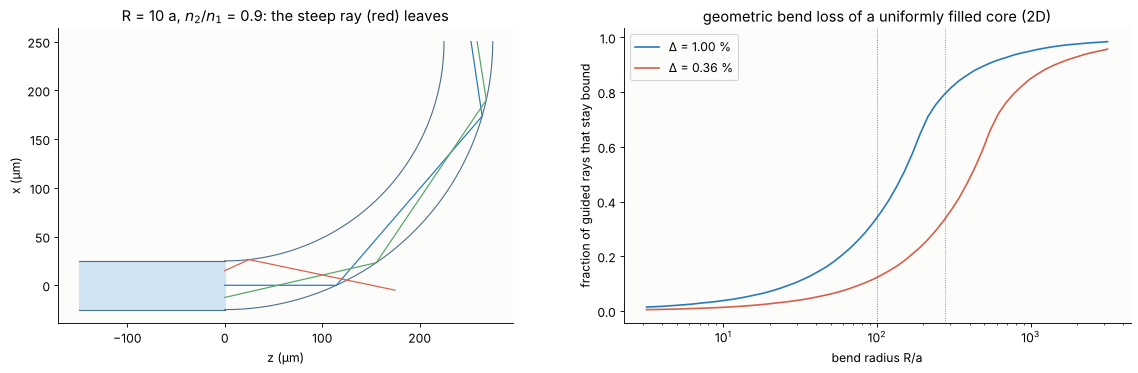

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8), gridspec_kw={"width_ratios": [1.1, 1]})
# a picture: rays entering a bend of radius 10 a
Rb = 10*a
t = np.linspace(0, np.pi/2, 200)
for rr in (Rb - a, Rb + a):
    axes[0].plot(rr*np.sin(t), Rb - rr*np.cos(t), color="#4a6f8a", lw=1)
axes[0].fill_between(np.linspace(-6*a, 0, 2), -a, a, color="#cfe3f3")
axes[0].plot([-6*a, 0], [-a, -a], color="#4a6f8a", lw=1); axes[0].plot([-6*a, 0], [a, a], color="#4a6f8a", lw=1)


def bend_trace(x0, th, Rb, a, ratio, n_bounce=12):
    """2D ray in a bend centred at (0, Rb), starting at z = 0, height x0, angle th
    (towards +x positive); ratio = n2/n1. Returns the points and whether it stays bound."""
    P = np.array([0.0, x0]); d = np.array([np.cos(th), np.sin(th)])
    C = np.array([0.0, Rb])
    pts = [P.copy()]
    ok = True
    for _ in range(n_bounce):
        best = None
        for rr in (Rb + a, Rb - a):
            # |P + s d - C| = rr
            q = P - C
            b = np.dot(q, d); c = np.dot(q, q) - rr**2
            disc = b**2 - c
            if disc < 0:
                continue
            for s in (-b - np.sqrt(disc), -b + np.sqrt(disc)):
                if s > 1E-9 and (best is None or s < best[0]):
                    best = (s, rr)
        s, rr = best
        P = P + s*d
        nrm = (P - C)/rr
        cos_inc = abs(np.dot(d, nrm))
        pts.append(P.copy())
        if rr == Rb + a and np.sqrt(1 - cos_inc**2) < ratio:
            ok = False
            pts.append(P + 2*a*d)
            break
        d = d - 2*np.dot(d, nrm)*nrm
        if np.arctan2(P[0], Rb - P[1]) > np.pi/2:
            break
    return np.array(pts), ok


ratio = 0.9    # a strongly guiding fibre for the picture: θc = 25.8°
th_c_pic = np.arccos(ratio)
for x0, th, c in ((0.0, 0.0, BLUE), (-0.5*a, 0.5*th_c_pic, GREEN), (0.6*a, 0.95*th_c_pic, RED)):
    pts, ok = bend_trace(x0, th, Rb, a, ratio)
    for k in range(1, len(pts)):          # end the drawing at the quarter turn (x = Rb)
        if pts[k, 1] > Rb:
            f = (Rb - pts[k - 1, 1])/(pts[k, 1] - pts[k - 1, 1])
            pts = np.vstack([pts[:k], pts[k - 1] + f*(pts[k] - pts[k - 1])])
            break
    axes[0].plot(pts[:, 0], pts[:, 1], color=c, lw=1.1)
axes[0].set_aspect("equal"); axes[0].set_xlabel("z (µm)"); axes[0].set_ylabel("x (µm)")
axes[0].set_title("R = 10 a, $n_2/n_1$ = 0.9: the steep ray (red) leaves")

R_over_a = np.logspace(0.5, 3.5, 60)
xs = rng.uniform(-a, a, 40000)
ths = rng.uniform(-1, 1, 40000)*theta_c
for D, c in ((0.01, BLUE), (0.0036, RED)):
    n2b = n1*np.sqrt(1 - 2*D)
    thc = np.arccos(n2b/n1)
    th_d = ths/theta_c*thc
    frac = np.array([np.mean((ra*a + xs)*np.cos(th_d)/(ra*a + a) >= n2b/n1) for ra in R_over_a])
    axes[1].semilogx(R_over_a, frac, color=c, label=f"Δ = {100*D:.2f} %")
    axes[1].axvline(1/D, color=c, ls=":", lw=0.8)
    print("Δ = {:.2f} %: half of the rays survive at R = {:.1f} a/Δ, 90 % at R = {:.1f} a/Δ".format(
          100*D, np.interp(0.5, frac, R_over_a)*D, np.interp(0.9, frac, R_over_a)*D))
axes[1].set_xlabel("bend radius R/a"); axes[1].set_ylabel("fraction of guided rays that stay bound")
axes[1].set_title("geometric bend loss of a uniformly filled core (2D)")
axes[1].legend()
plt.tight_layout()
plt.show()

The rays close to the critical angle are lost in any bend, however gentle;
the bend takes half of the rays at $R \approx 1.5\,a/\Delta$ (the dotted lines
mark $a/\Delta$) and still 10 % at $R \approx 5a/\Delta$, with a curve that
depends on $\Delta$ only through $R\Delta/a$. A 50 µm core with
$\Delta = 1\,\%$ loses half of a full launch at a radius of 4 mm, which a
cable never imposes, but which is
exactly how a **mode stripper** or a mandrel wrap removes the highest
order modes on purpose. The single-mode fibre has no rays to strip; its
bend loss is a wave effect (notebook 116, fibre modes, section 6).

## Summary

- **NA:** total internal reflection accepts $n_0\sin\theta_{max} =
  \sqrt{n_1^2 - n_2^2} = n_1\sqrt{2\Delta}$: 0.12 for a single-mode fibre,
  0.2 to 0.28 for multimode fibres. A fibre takes the fraction
  $\mathrm{NA}^2$ of a Lambertian source on its face (Monte Carlo against
  formula), its étendue is $\pi^2a^2\mathrm{NA}^2$.
- **Skew rays** keep $\bar\beta = n_1\cos\theta_z$ and
  $\bar l = n_1\sin\theta_z r_{min}/a$; bound rays are those within the NA,
  tunnelling rays add about as much again in short fibres and leak away.
- **Graded index:** rays become sinusoids of pitch
  $2\pi a/\sqrt{2\Delta}$ (1.1 mm), traced with `grin.trace()`.
- **Intermodal dispersion:** $Ln_1\Delta/c$ (49 ns/km) for the step,
  $Ln_1\Delta^2/(2c)$ for the parabola, and an rms spread of a few ps/km at
  $\alpha_{opt} = 2 - 12\Delta/5$. The traced ray times lie on the WKB
  group delays of the modes. 5 % off the optimal $\alpha$ costs a factor
  of ten.
- **Launch and mixing:** restricted launches spread less; mode mixing
  brings both to one equilibrium and turns the growth from $L$ into
  $\sqrt{L}$.
- **Bends** strip the steepest rays at any radius and half of them at
  $R \approx 1.5\,a/\Delta$.

In [14]:
print("run time: {:.0f} s".format(time.time() - t_start))

run time: 6 s


## References

- A. W. Snyder and J. D. Love, *Optical Waveguide Theory*, Chapman and
  Hall (1983), chapters 1 to 5 (rays, invariants, tunnelling rays).
- D. Gloge and E. A. J. Marcatili, "Multimode theory of graded-core
  fibers", Bell Syst. Tech. J. 52, 1563–1578 (1973).
- R. Olshansky and D. B. Keck, "Pulse broadening in graded-index optical
  fibers", Appl. Opt. 15, 483–491 (1976).
- G. Keiser, *Optical Fiber Communications*, 5th ed., McGraw-Hill (2015),
  chapters 2 and 3.
- J. M. Senior, *Optical Fiber Communications*, 3rd ed., Prentice Hall
  (2009), chapters 2 and 3.
- TIA-492AAAD and IEC 60793-2-10 (OM4 fibre), IEC 61280-4-1 (encircled
  flux launch).